# Discriminative Project – Milestone 2: Object Detection

IE 7615 Deep Learning for AI  
Study Group 6: Bingyan Zhu, Muhan Li, Ruoxi Chen

We train YOLOv8n with object boxes on single photos and grid images. Official COCO weights are used to keep evaluation photos separate from earlier training.


## Setup


In [1]:
import os, sys, subprocess
os.environ['WANDB_MODE'] = 'disabled'
os.environ['OMP_NUM_THREADS'] = '2'
print('Installing Ultralytics...', flush=True)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.175'])
import torch
from google.colab import drive
drive.mount('/content/drive')
if not torch.cuda.is_available():
    raise RuntimeError('Enable a GPU in Colab and rerun this cell.')
torch.set_num_threads(2)
print('GPU:', torch.cuda.get_device_name(0), flush=True)
print('PyTorch:', torch.__version__)


Installing Ultralytics...
Mounted at /content/drive
GPU: NVIDIA A100-SXM4-40GB
PyTorch: 2.11.0+cu130


## Settings


In [2]:
import json, time, uuid, hashlib, shutil, math, random, threading, zipfile, csv
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from collections import Counter, defaultdict, deque
from contextlib import contextmanager
from functools import lru_cache
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm
from ultralytics import YOLO
import ultralytics
import yaml

SOURCE_DIR = Path('/content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/IE7615 Deep Learning for AI')
ANNOTATION_JSON = Path('/content/drive/MyDrive/IE7615_annotations/annotations_all.json')
V4_WEIGHT = Path('/content/drive/MyDrive/IE7615_models/v4_candidate_best.pt')
V4_OUTPUT_ROOT = Path('/content/drive/MyDrive/IE7615_outputs_milestone2_v4')

SEED = 42
CANVAS = 640
GRID_MARGIN = 8
TILE_SCALE = (0.85, 1.00)
ROT_DEG = 5
N_TRAIN_GRIDS = 6000
N_VAL_GRIDS = 600
N_TEST_GRIDS = 600
EPOCHS, PATIENCE, LR = 100, 20, 1e-4
gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
BATCH = 32 if gpu_gb >= 20 else 16
WORKERS = 2
SAVE_DATASET_ZIP = True
EXPECTED_IDS = {f'OBJ{i:03d}' for i in range(1, 74)}
EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

random.seed(SEED)
np.random.seed(SEED)
RUN_ID = datetime.now(timezone.utc).strftime('run_%Y%m%d_%H%M%S_UTC_') + uuid.uuid4().hex[:8]
OUT_DIR = Path('/content/drive/MyDrive/IE7615_outputs_milestone2_v5') / RUN_ID
LOCAL = Path('/content/ie7615_milestone2_v5') / RUN_ID
DATASET = LOCAL / 'yolo_dataset'
SECOND_BACKUP = Path('/content/drive/MyDrive/IE7615_models/v5') / RUN_ID
for directory in (OUT_DIR, LOCAL, SECOND_BACKUP):
    directory.mkdir(parents=True, exist_ok=False)
print('Output folder:', OUT_DIR, flush=True)
print('Second model backup:', SECOND_BACKUP)
print(f'batch={BATCH}, max epochs: {EPOCHS}, patience: {PATIENCE} epochs.')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Output folder: /content/drive/MyDrive/IE7615_outputs_milestone2_v5/run_20261019_020402_UTC_8158f013
Second model backup: /content/drive/MyDrive/IE7615_models/v5/run_20261019_020402_UTC_8158f013
batch=32, max epochs: 100, patience: 20 epochs.


In [3]:
def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def say(message):
    print(time.strftime('[%H:%M:%S] '), message, sep='', flush=True)

@contextmanager
def heartbeat(message, seconds=20):
    stop = threading.Event()
    start = time.monotonic()
    def report():
        while not stop.wait(seconds):
            say(f'{message}: running, elapsed {time.monotonic()-start:.0f} s')
    thread = threading.Thread(target=report, daemon=True)
    thread.start()
    try:
        say(message)
        yield
    finally:
        stop.set()
        thread.join(timeout=1)

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp_' + uuid.uuid4().hex[:8])
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def copy_verified(source, destination):
    source, destination = Path(source), Path(destination)
    if not source.is_file() or source.stat().st_size == 0:
        raise FileNotFoundError(f'Missing or empty source file: {source}')
    expected = sha256(source)
    destination.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(3):
        temporary = destination.with_name(destination.name + '.tmp_' + uuid.uuid4().hex[:8])
        try:
            shutil.copyfile(source, temporary)
            if sha256(temporary) != expected:
                raise IOError('Checksum mismatch after copy')
            temporary.replace(destination)
            if sha256(destination) != expected:
                raise IOError('Checksum mismatch after save')
            return expected
        except Exception:
            temporary.unlink(missing_ok=True)
            if attempt == 2:
                raise
            say(f'Drive write failed, retry {attempt+2}/3: {destination.name}')
            time.sleep(2)

def require(condition, message):
    if not condition:
        raise ValueError(message)


## Weights and Labels

The earlier model provides the class IDs. Training starts from official COCO weights below.


In [4]:
if not V4_WEIGHT.is_file():
    found = []
    if V4_OUTPUT_ROOT.is_dir():
        with heartbeat('Checking earlier model weights'):
            for run in sorted(V4_OUTPUT_ROOT.glob('run_*')):
                options = [run/'v4_candidate_best.pt',
                           run/'runs/yolov8_custom_v4/weights/best.pt']
                hit = next((path for path in options if path.is_file()), None)
                if hit is not None:
                    found.append(hit)
    if len(found) == 1:
        V4_WEIGHT = found[0]
    elif len(found) > 1:
        print('\n'.join(map(str, found)))
        raise ValueError('Multiple runs found. Set V4_WEIGHT to the required checkpoint.')
    else:
        from google.colab import files
        say('Earlier weights not found. Upload v4_candidate_best.pt.')
        previous = Path.cwd()
        upload_dir = LOCAL / 'weight_upload'
        upload_dir.mkdir(exist_ok=True)
        try:
            os.chdir(upload_dir)
            uploaded = files.upload()
        finally:
            os.chdir(previous)
        pt_files = [upload_dir/name for name in uploaded if Path(name).suffix.lower() == '.pt']
        require(len(pt_files) == 1, 'Upload one earlier .pt checkpoint.')
        V4_WEIGHT = pt_files[0]

with heartbeat('Loading earlier weights and checking class IDs'):
    V4_SHA256 = sha256(V4_WEIGHT)
    INIT_WEIGHT = LOCAL / 'v4_initial.pt'
    copy_verified(V4_WEIGHT, INIT_WEIGHT)
    initial_model = YOLO(str(INIT_WEIGHT))
    require(initial_model.task == 'detect', 'A detection checkpoint is required.')
    ids = [initial_model.names[i] for i in range(len(initial_model.names))]
    require(len(ids) == 73 and set(ids) == EXPECTED_IDS, 'Checkpoint classes must be OBJ001 to OBJ073.')
    id2idx = {oid: i for i, oid in enumerate(ids)}
    del initial_model
say(f'Earlier weights: {V4_WEIGHT}')

if not ANNOTATION_JSON.is_file():
    raise FileNotFoundError(f'Place the complete annotations at {ANNOTATION_JSON}, then rerun this cell.')
annotation_bytes = ANNOTATION_JSON.read_bytes()
ANNOTATION_SHA256 = hashlib.sha256(annotation_bytes).hexdigest()
raw_annotations = json.loads(annotation_bytes.decode('utf-8-sig'))
require(set(raw_annotations) == {'format_version', 'bbox_format', 'images'}, 'Invalid top-level JSON fields.')
require(raw_annotations['format_version'] == '1.0' and raw_annotations['bbox_format'] == 'xyxy_pixels',
        'Expected annotation format: 1.0 / xyxy_pixels.')
records_by_name = {}
for row in raw_annotations['images']:
    require(set(row) == {'file_name', 'width', 'height', 'objects'}, f'Invalid image fields: {row}')
    relative = PurePosixPath(row['file_name'])
    require(not relative.is_absolute() and len(relative.parts) == 2 and '..' not in relative.parts
            and '\\' not in row['file_name'], f'Expected a relative path: images_OBJxxx/filename: {relative}')
    folder_id = relative.parts[0].removeprefix('images_')
    require(relative.parts[0] == 'images_' + folder_id and folder_id in EXPECTED_IDS
            and relative.suffix.lower() in EXTS, f'Invalid image path: {relative}')
    require(str(relative) not in records_by_name, f'Duplicate image in JSON: {relative}')
    w, h = row['width'], row['height']
    require(type(w) is int and type(h) is int and w > 0 and h > 0, f'Invalid image dimensions: {relative}')
    require(isinstance(row['objects'], list), f'objects must be a list: {relative}')
    for obj in row['objects']:
        require(set(obj) == {'id', 'bbox'} and obj['id'] in EXPECTED_IDS, f'Invalid object ID or fields: {relative}')
        box = obj['bbox']
        require(isinstance(box, list) and len(box) == 4 and
                all(type(v) in (int, float) and math.isfinite(v) for v in box), f'Invalid box coordinates: {relative}')
        x1, y1, x2, y2 = box
        require(0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h, f'Box outside source image: {relative} {box}')
    records_by_name[str(relative)] = {**row, 'folder_id': folder_id}
require({r['folder_id'] for r in records_by_name.values()} == EXPECTED_IDS, 'Annotations must cover all 73 folders.')
positive_classes = {obj['id'] for r in records_by_name.values() for obj in r['objects']}
require(positive_classes == EXPECTED_IDS, f'Classes without object boxes: {sorted(EXPECTED_IDS-positive_classes)}')
copy_verified(ANNOTATION_JSON, OUT_DIR/'inputs/annotations_all.json')
write_json(OUT_DIR/'inputs/initial_weight.json', {'path': str(V4_WEIGHT), 'sha256': V4_SHA256,
           'names': ids, 'annotation_sha256': ANNOTATION_SHA256, 'source_dir': str(SOURCE_DIR),
           'orientation': 'raw decoded pixels; no EXIF rotation'})
say(f'JSON check passed: {len(records_by_name)} images; images with objects=[] are excluded.')


[02:04:08] Checking earlier model weights
[02:04:08] Earlier weights not found. Upload v4_candidate_best.pt.


Saving v4_candidate_best.pt to v4_candidate_best.pt
[02:06:01] Loading earlier weights and checking class IDs
[02:06:02] Earlier weights: /content/ie7615_milestone2_v5/run_20261019_020402_UTC_8158f013/weight_upload/v4_candidate_best.pt
[02:06:02] JSON check passed: 7343 images; images with objects=[] are excluded.


## Source Split

We remove duplicate photos before the 70/15/15 split. Grid images are built separately for each split.


In [11]:
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED

COPY_WORKERS = 8
source_pools = None

require(SOURCE_DIR.is_dir(), f'Source folder not found: {SOURCE_DIR}')
all_names = set()

with heartbeat('Checking source filenames against JSON'):
    for oid in tqdm(ids, desc='Checking 73 source folders'):
        folder = SOURCE_DIR / ('images_' + oid)
        require(folder.is_dir(), f'Missing source folder: {folder}')
        all_names.update(
            f'{folder.name}/{p.name}'
            for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in EXTS
        )

missing_images = sorted(set(records_by_name) - all_names)
missing_labels = sorted(all_names - set(records_by_name))

require(
    not missing_images,
    f'Images referenced in JSON are missing; first 10: {missing_images[:10]}.'
)
require(
    not missing_labels,
    f'Images without annotations; first 10: {missing_labels[:10]}.'
)
require(
    shutil.disk_usage('/content').free > 20*1024**3,
    'Less than 20 GB of local disk space available.'
)

cache_key = hashlib.sha256(
    (str(SOURCE_DIR) + ANNOTATION_SHA256).encode()
).hexdigest()[:16]

LOCAL_SRC = Path('/content/ie7615_v5_source') / cache_key
LOCAL_SRC.mkdir(parents=True, exist_ok=True)

for oid in ids:
    (LOCAL_SRC / ('images_' + oid)).mkdir(exist_ok=True)


def inspect_source(payload, name, row):
    with Image.open(BytesIO(payload)) as opened:
        with opened.convert('RGB') as im:
            require(
                im.size == (row['width'], row['height']),
                f'Image size differs from JSON: {name}, actual size: {im.size}'
            )
            pixel_hash = hashlib.sha256(
                f'{im.width}x{im.height}:'.encode() + im.tobytes()
            ).hexdigest()

    return {
        **row,
        'file_sha256': hashlib.sha256(payload).hexdigest(),
        'pixel_sha256': pixel_hash
    }


def cache_one(item, source_root=SOURCE_DIR, cache_root=LOCAL_SRC):
    name, row = item
    local_path = cache_root / name

    if local_path.is_file():
        try:
            return inspect_source(
                local_path.read_bytes(), name, row
            ), True
        except OSError:
            pass

    for attempt in range(3):
        temporary = None
        try:
            payload = (source_root / name).read_bytes()
            record = inspect_source(payload, name, row)

            temporary = local_path.with_name(
                local_path.name + '.part_' + uuid.uuid4().hex[:8]
            )
            temporary.write_bytes(payload)
            temporary.replace(local_path)

            return record, False

        except OSError as exc:
            if attempt == 2:
                raise RuntimeError(
                    f'Read or cache failed after 3 attempts: {name}\n{exc}'
                ) from exc
            time.sleep(attempt + 1)

        finally:
            if temporary is not None:
                temporary.unlink(missing_ok=True)


items = iter(sorted(records_by_name.items()))
source_records = []
cache_hits = new_copies = 0
started = time.monotonic()

executor = ThreadPoolExecutor(max_workers=COPY_WORKERS)
pending = {}


def submit_next():
    item = next(items, None)
    if item is not None:
        pending[executor.submit(cache_one, item)] = item[0]


try:
    for _ in range(COPY_WORKERS * 2):
        submit_next()

    with heartbeat(f'{COPY_WORKERS} cache workers; reusing local files'):
        with tqdm(
            total=len(records_by_name),
            desc='Caching and checking images',
            unit='img'
        ) as bar:
            while pending:
                completed, _ = wait(
                    pending,
                    timeout=1,
                    return_when=FIRST_COMPLETED
                )

                for future in completed:
                    pending.pop(future)
                    record, cached = future.result()
                    source_records.append(record)

                    cache_hits += int(cached)
                    new_copies += int(not cached)
                    bar.update(1)

                    if len(source_records) % 20 == 0:
                        bar.set_postfix(
                            {'cached': cache_hits, 'copied': new_copies},
                            refresh=False
                        )

                    submit_next()

except BaseException:
    for future in pending:
        future.cancel()
    executor.shutdown(wait=False, cancel_futures=True)
    say('Stopped. Cached files are kept; fix the error and rerun this cell.')
    raise

else:
    executor.shutdown(wait=True)

source_records.sort(key=lambda row: row['file_name'])

require(
    len(source_records) == len(records_by_name),
    'Source check incomplete. Finish it before training.'
)

say(
    f'Cache check done: reused {cache_hits} images, copied {new_copies} images, '
    f'elapsed {time.monotonic()-started:.0f} s.'
)

by_content = defaultdict(list)
for row in source_records:
    by_content[row['pixel_sha256']].append(row)

unique_positive, duplicate_rows = [], []

for group in by_content.values():
    signatures = {
        tuple(sorted(obj['id'] for obj in r['objects']))
        for r in group
    }
    require(
        len(signatures) == 1,
        f'Conflicting annotations for identical images: '
        f'{[r["file_name"] for r in group]}'
    )

    if not group[0]['objects']:
        continue

    require(
        len({r['folder_id'] for r in group}) == 1,
        f'Identical object image found in multiple class folders: '
        f'{[r["file_name"] for r in group]}'
    )

    representative = sorted(
        group, key=lambda r: r['file_name']
    )[0]
    unique_positive.append(representative)

    for duplicate in group:
        if duplicate is not representative:
            duplicate_rows.append({
                'kept': representative['file_name'],
                'skipped': duplicate['file_name']
            })

split_rng = random.Random(SEED)
source_pools = {
    split: {oid: [] for oid in ids}
    for split in ('train', 'val', 'test')
}

for oid in ids:
    rows = sorted(
        (r for r in unique_positive if r['folder_id'] == oid),
        key=lambda r: r['file_name']
    )
    require(
        len(rows) >= 10,
        f'{oid} has only {len(rows)} unique positive photos. Check the annotations.'
    )

    split_rng.shuffle(rows)
    n_val = max(1, round(len(rows) * 0.15))
    n_test = max(1, round(len(rows) * 0.15))

    source_pools['val'][oid] = rows[:n_val]
    source_pools['test'][oid] = rows[n_val:n_val+n_test]
    source_pools['train'][oid] = rows[n_val+n_test:]

for split in source_pools:
    present = {
        obj['id']
        for pool in source_pools[split].values()
        for r in pool
        for obj in r['objects']
    }
    require(
        present == EXPECTED_IDS,
        f'{split} is missing boxes for these classes: '
        f'{sorted(EXPECTED_IDS-present)}'
    )

split_hashes = {
    split: {
        r['pixel_sha256']
        for pool in source_pools[split].values()
        for r in pool
    }
    for split in source_pools
}

for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    require(
        not split_hashes[a] & split_hashes[b],
        f'{a}/{b} contain duplicate images.'
    )

split_manifest = [
    {
        'split': split,
        'id': oid,
        'file_name': r['file_name'],
        'pixel_sha256': r['pixel_sha256'],
        'file_sha256': r['file_sha256']
    }
    for split in source_pools
    for oid in ids
    for r in source_pools[split][oid]
]

write_json(OUT_DIR/'source_split.json', split_manifest)
write_json(OUT_DIR/'duplicate_sources.json', duplicate_rows)

say(
    f'Source check done; skipped backgrounds: '
    f'{sum(not r["objects"] for r in source_records)} images, '
    f'duplicates removed: {len(duplicate_rows)} images.'
)

for split in source_pools:
    say(
        f'{split}: '
        f'{sum(map(len, source_pools[split].values()))} unique positive source photos'
    )

[02:23:53] Checking source filenames against JSON


Checking 73 source folders:   0%|          | 0/73 [00:00<?, ?it/s]

[02:23:56] 8 cache workers; reusing local files


Caching and checking images:   0%|          | 0/7343 [00:00<?, ?img/s]

[02:24:16] 8 cache workers; reusing local files: running, elapsed 20 s
[02:24:36] 8 cache workers; reusing local files: running, elapsed 40 s
[02:24:56] 8 cache workers; reusing local files: running, elapsed 60 s
[02:25:16] 8 cache workers; reusing local files: running, elapsed 80 s
[02:25:36] 8 cache workers; reusing local files: running, elapsed 100 s
[02:25:56] 8 cache workers; reusing local files: running, elapsed 120 s
[02:26:16] 8 cache workers; reusing local files: running, elapsed 140 s
[02:26:36] 8 cache workers; reusing local files: running, elapsed 160 s
[02:26:56] 8 cache workers; reusing local files: running, elapsed 180 s
[02:27:16] 8 cache workers; reusing local files: running, elapsed 200 s
[02:27:36] 8 cache workers; reusing local files: running, elapsed 220 s
[02:27:56] 8 cache workers; reusing local files: running, elapsed 240 s
[02:28:13] Cache check done: reused 1705 images, copied 5638 images, elapsed 257 s.
[02:28:13] Source check done; skipped backgrounds: 393 i

## Dataset

Each split includes single photos, 2×2 grids and 3×3 grids with object boxes.


In [12]:
@lru_cache(maxsize=256)
def read_source(name):
    with Image.open(LOCAL_SRC/name) as opened:
        return opened.convert('RGB')

def transform_photo(im, objects, angle, target_w, target_h, fill, background):
    w, h = im.size
    theta = math.radians(angle)
    c, s = math.cos(theta), math.sin(theta)
    matrix = np.array([[c, -s], [s, c]], dtype=np.float64)
    corners = np.array([[0, 0], [w, 0], [w, h], [0, h]], dtype=np.float64) @ matrix.T
    offset = corners.min(axis=0)
    extent = corners.max(axis=0)-offset
    rw, rh = np.maximum(1, np.ceil(extent).astype(int))
    inv = np.linalg.inv(matrix)
    translation = inv @ offset
    coefficients = (*inv[0], translation[0], *inv[1], translation[1])
    rotated = im.transform((int(rw), int(rh)), Image.Transform.AFFINE, coefficients,
                           Image.Resampling.BICUBIC, fillcolor=background)
    scale = min(target_w/rw, target_h/rh)*fill
    dw, dh = max(1, round(rw*scale)), max(1, round(rh*scale))
    resized = rotated.resize((dw, dh), Image.Resampling.LANCZOS)
    factors = np.array([dw/rw, dh/rh])
    transformed = []
    for obj in objects:
        x1, y1, x2, y2 = obj['bbox']
        polygon = np.array([[x1,y1],[x2,y1],[x2,y2],[x1,y2]], dtype=float)
        polygon = (polygon @ matrix.T-offset)*factors
        lo, hi = polygon.min(axis=0), polygon.max(axis=0)
        transformed.append({'id': obj['id'], 'bbox': [float(lo[0]), float(lo[1]), float(hi[0]), float(hi[1])]})
    return resized, transformed

def save_example(im, objects, split, name, layout, sources):
    w, h = im.size
    image_path = DATASET/'images'/split/name
    label_path = DATASET/'labels'/split/Path(name).with_suffix('.txt')
    image_path.parent.mkdir(parents=True, exist_ok=True)
    label_path.parent.mkdir(parents=True, exist_ok=True)
    lines = []
    for obj in objects:
        x1, y1, x2, y2 = obj['bbox']
        require(-1e-5 <= x1 < x2 <= w+1e-5 and -1e-5 <= y1 < y2 <= h+1e-5,
                f'Transformed box outside image: {name}, {obj}')
        x1, y1, x2, y2 = max(0,x1), max(0,y1), min(w,x2), min(h,y2)
        lines.append(f'{id2idx[obj["id"]]} {(x1+x2)/2/w:.8f} {(y1+y2)/2/h:.8f} {(x2-x1)/w:.8f} {(y2-y1)/h:.8f}')
    require(bool(lines), f'Generated image has no objects: {name}')
    im.save(image_path, quality=95)
    label_path.write_text('\n'.join(lines)+'\n', encoding='utf-8')
    return {'image': name, 'split': split, 'layout': layout, 'sources': sources, 'objects': objects,
            'width': w, 'height': h}

def make_grid(rows, g, rng):
    background = tuple(rng.randint(160, 240) for _ in range(3))
    canvas = Image.new('RGB', (CANVAS, CANVAS), background)
    edges = [round(i*CANVAS/g) for i in range(g+1)]
    objects = []
    for index, row in enumerate(rows):
        cell_y, cell_x = divmod(index, g)
        left, right = edges[cell_x], edges[cell_x+1]
        top, bottom = edges[cell_y], edges[cell_y+1]
        picture, boxes = transform_photo(read_source(row['file_name']), row['objects'],
                                         rng.uniform(-ROT_DEG,ROT_DEG),
                                         right-left-2*GRID_MARGIN, bottom-top-2*GRID_MARGIN,
                                         rng.uniform(*TILE_SCALE), background)
        x = left+(right-left-picture.width)//2
        y = top+(bottom-top-picture.height)//2
        canvas.paste(picture, (x,y))
        for obj in boxes:
            x1,y1,x2,y2 = obj['bbox']
            objects.append({'id': obj['id'], 'bbox': [x+x1,y+y1,x+x2,y+y2]})
    return canvas, objects

dataset_manifest = []
coverage = []
for split, n_grids in [('train',N_TRAIN_GRIDS), ('val',N_VAL_GRIDS), ('test',N_TEST_GRIDS)]:
    require(n_grids % 2 == 0, 'Grid count must be even.')
    rng = random.Random(SEED+{'train':100,'val':200,'test':300}[split])
    rows = [r for oid in ids for r in source_pools[split][oid]]
    with heartbeat(f'Generating {split} single photos and grids'):
        for index, row in enumerate(tqdm(rows, desc=f'{split} single photos')):
            name = f'{split}_single_{index:05d}.jpg'
            record = save_example(read_source(row['file_name']), row['objects'], split, name, 'single', [row['file_name']])
            dataset_manifest.append(record)
        queues = {oid: deque() for oid in ids}
        usage = Counter()
        def next_source(oid):
            if not queues[oid]:
                candidates = list(source_pools[split][oid])
                rng.shuffle(candidates)
                queues[oid].extend(candidates)
            item = queues[oid].popleft()
            usage[item['file_name']] += 1
            return item
        layouts = [2]*(n_grids//2)+[3]*(n_grids//2)
        rng.shuffle(layouts)
        n_slots = sum(g*g for g in layouts)
        schedule = [ids[i%len(ids)] for i in range(n_slots)]
        rng.shuffle(schedule)
        schedule = iter(schedule)
        for index, g in enumerate(tqdm(layouts, desc=f'{split} grids')):
            selected = [next_source(next(schedule)) for _ in range(g*g)]
            im, boxes = make_grid(selected, g, rng)
            record = save_example(im, boxes, split, f'{split}_grid_{index:05d}.jpg', f'{g}x{g}',
                                  [r['file_name'] for r in selected])
            dataset_manifest.append(record)
    coverage.extend({'split':split, 'file_name':r['file_name'], 'single_uses':1,
                     'grid_uses':usage[r['file_name']]} for r in rows)
read_source.cache_clear()
write_json(DATASET/'dataset_manifest.json', dataset_manifest)
write_json(OUT_DIR/'source_coverage.json', coverage)

def write_dataset_configs():
    names = dict(enumerate(ids))
    base = {'train':'images/train', 'val':'images/val', 'test':'images/test', 'names':names}
    (DATASET/'data.yaml').write_text(yaml.safe_dump(base, sort_keys=False), encoding='utf-8')
    for split in ('val','test'):
        for layout in ('single','2x2','3x3'):
            chosen = [r for r in dataset_manifest if r['split']==split and r['layout']==layout]
            listing = f'{split}_{layout}.txt'
            (DATASET/listing).write_text(''.join(f'./images/{split}/{r["image"]}\n' for r in chosen), encoding='utf-8')
            config = {**base, split:listing}
            (DATASET/f'data_{split}_{layout}.yaml').write_text(yaml.safe_dump(config, sort_keys=False), encoding='utf-8')
write_dataset_configs()
YAML_PATH = DATASET/'data.yaml'
counts = Counter((r['split'],r['layout']) for r in dataset_manifest)
print(pd.DataFrame([{'split':s,'layout':g,'images':n} for (s,g),n in counts.items()]).to_string(index=False))
say(f'Generated {len(dataset_manifest)} images, {sum(len(r["objects"]) for r in dataset_manifest)} object boxes.')


[02:28:21] Generating train single photos and grids


train single photos:   0%|          | 0/4875 [00:00<?, ?it/s]

train grids:   0%|          | 0/6000 [00:00<?, ?it/s]

[02:28:41] Generating train single photos and grids: running, elapsed 20 s
[02:29:01] Generating train single photos and grids: running, elapsed 40 s
[02:29:21] Generating train single photos and grids: running, elapsed 60 s
[02:29:41] Generating train single photos and grids: running, elapsed 80 s
[02:30:01] Generating train single photos and grids: running, elapsed 100 s
[02:30:21] Generating train single photos and grids: running, elapsed 120 s
[02:30:41] Generating train single photos and grids: running, elapsed 140 s
[02:31:01] Generating train single photos and grids: running, elapsed 160 s
[02:31:21] Generating train single photos and grids: running, elapsed 180 s
[02:31:41] Generating train single photos and grids: running, elapsed 200 s
[02:32:01] Generating train single photos and grids: running, elapsed 220 s
[02:32:21] Generating train single photos and grids: running, elapsed 240 s
[02:32:41] Generating train single photos and grids: running, elapsed 260 s
[02:33:01] Gener

val single photos:   0%|          | 0/1027 [00:00<?, ?it/s]

val grids:   0%|          | 0/600 [00:00<?, ?it/s]

[02:33:52] Generating val single photos and grids: running, elapsed 20 s
[02:34:04] Generating test single photos and grids


test single photos:   0%|          | 0/1027 [00:00<?, ?it/s]

test grids:   0%|          | 0/600 [00:00<?, ?it/s]

[02:34:24] Generating test single photos and grids: running, elapsed 20 s
split layout  images
train single    4875
train    2x2    3000
train    3x3    3000
  val single    1027
  val    2x2     300
  val    3x3     300
 test single    1027
 test    2x2     300
 test    3x3     300
[02:34:36] Generated 14129 images, 54528 object boxes.


## Label Preview


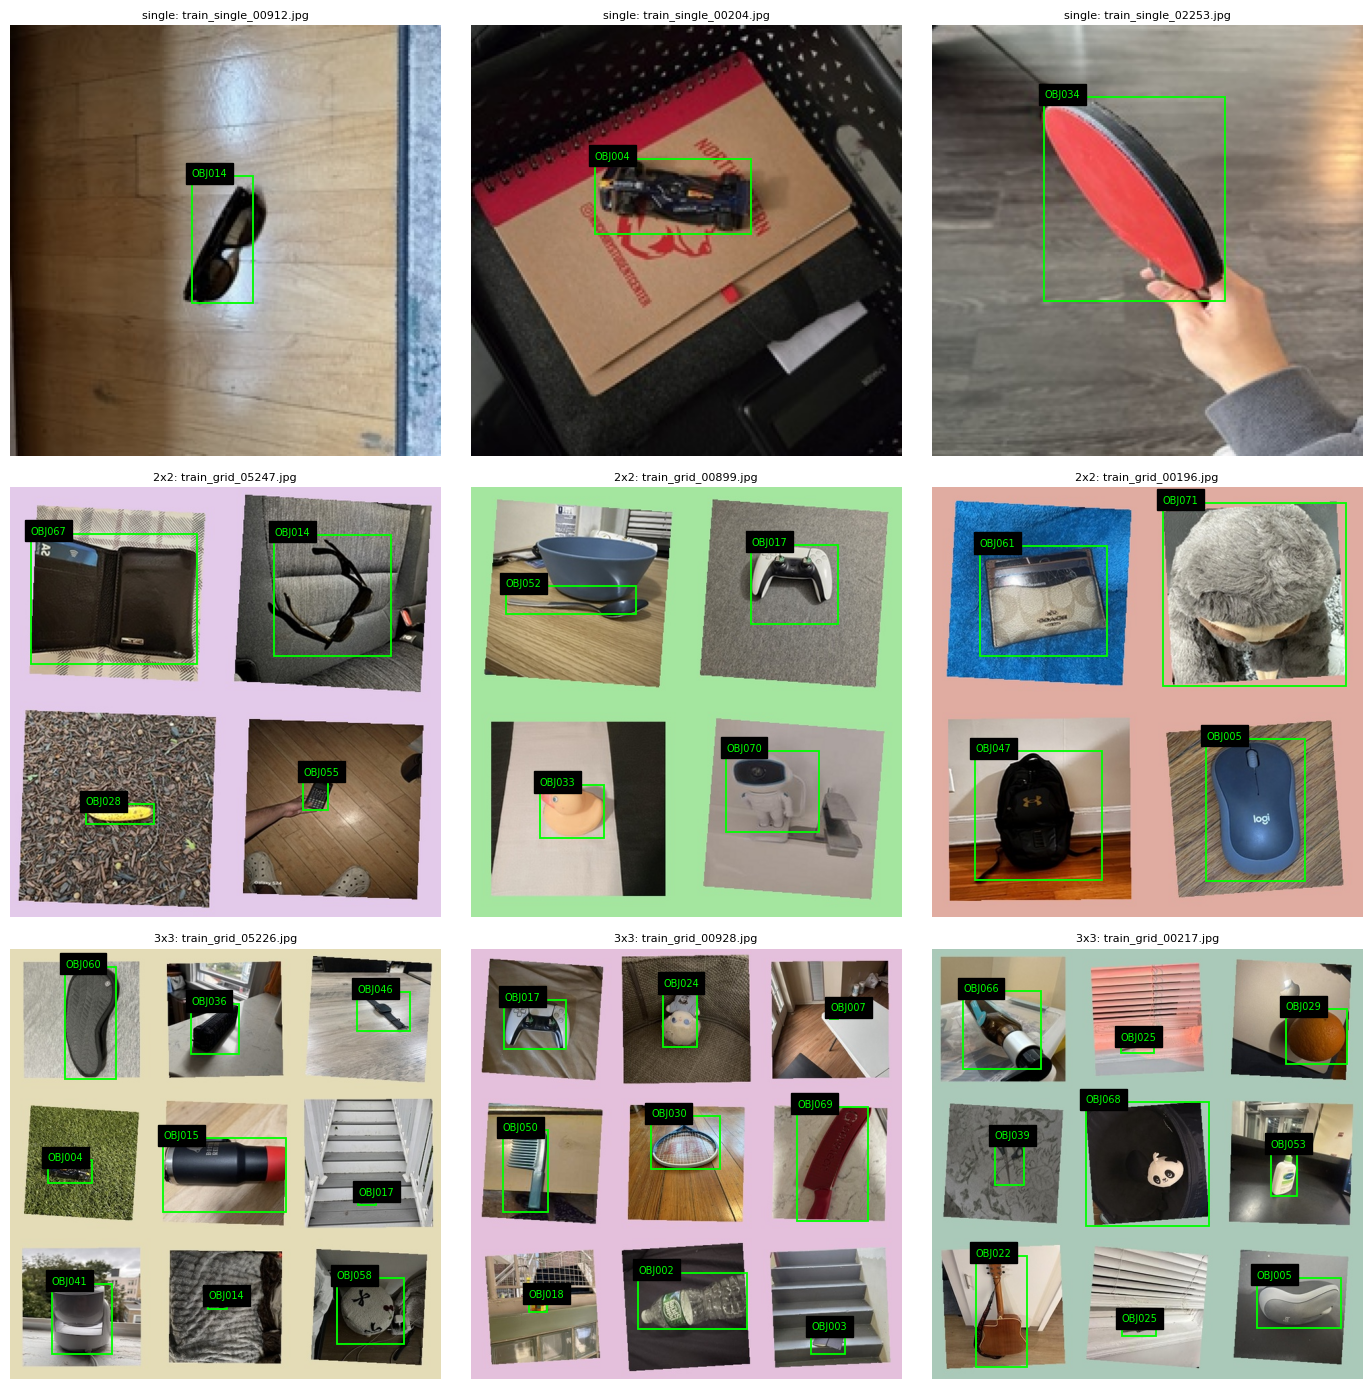

In [13]:
def show_labels(ax, record):
    path = DATASET/'images'/record['split']/record['image']
    with Image.open(path) as opened:
        ax.imshow(opened.convert('RGB'))
    for obj in record['objects']:
        x1,y1,x2,y2 = obj['bbox']
        ax.add_patch(patches.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='lime',linewidth=1.3))
        ax.text(x1,y1,obj['id'],fontsize=7,color='lime',backgroundcolor='black')
    ax.set_title(f'{record["layout"]}: {record["image"]}',fontsize=8)
    ax.axis('off')

fig, axes = plt.subplots(3,3,figsize=(14,14))
for row, layout in enumerate(('single','2x2','3x3')):
    examples = [r for r in dataset_manifest if r['split']=='train' and r['layout']==layout]
    chosen = random.Random(SEED).sample(examples,3)
    for ax, record in zip(axes[row],chosen):
        show_labels(ax,record)
plt.tight_layout()
plt.savefig(OUT_DIR/'label_preview.png',dpi=130)
plt.show()


## Save Dataset


In [14]:
config_record = {'run_id':RUN_ID, 'version':'V5', 'seed':SEED, 'source_dir':str(SOURCE_DIR),
    'annotation_file':str(ANNOTATION_JSON), 'annotation_sha256':ANNOTATION_SHA256,
    'initial_weight':str(V4_WEIGHT), 'initial_weight_sha256':V4_SHA256,
    'names':ids, 'canvas':CANVAS, 'rotation_deg':ROT_DEG, 'tile_scale':list(TILE_SCALE),
    'epochs_max':EPOCHS, 'patience':PATIENCE, 'batch':BATCH, 'lr0':LR,
    'optimizer':'AdamW', 'workers':WORKERS, 'ultralytics':ultralytics.__version__,
    'torch':torch.__version__, 'gpu':torch.cuda.get_device_name(0),
    'label_target':'visible object bounding boxes; not photo tile boundaries',
    'orientation':'raw decoded pixels; no EXIF rotation',
    'split_method':'unique decoded source photos, stratified by folder, 70/15/15',
    'initial_weights_may_have_seen_holdout_photos':True,
    'data_counts':[{'split':s,'layout':g,'images':n} for (s,g),n in counts.items()]}
write_json(OUT_DIR/'run_config.json',config_record)
copy_verified(DATASET/'dataset_manifest.json',OUT_DIR/'dataset_manifest.json')
if SAVE_DATASET_ZIP:
    with heartbeat('Saving dataset archive to Drive'):
        archive = LOCAL/'yolo_dataset.zip'
        paths = sorted(p for p in DATASET.rglob('*') if p.is_file())
        with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_STORED) as bundle:
            for path in tqdm(paths,desc='Packing dataset'):
                bundle.write(path,'yolo_dataset/'+path.relative_to(DATASET).as_posix())
        copy_verified(archive,OUT_DIR/'dataset/yolo_dataset.zip')
        archive.unlink()
say('Dataset and settings saved. Training uses local images.')


[02:35:21] Saving dataset archive to Drive


Packing dataset:   0%|          | 0/28272 [00:00<?, ?it/s]

[02:35:39] Dataset and settings saved. Training uses local images.


## Training

We use AdamW with light augmentation. Mosaic and mixup are off.


In [15]:
require(
    not (LOCAL/'runs/yolov8_custom_v5').exists(),
    'Training already started. Rerun Settings to create a new run.'
)

with heartbeat('Loading official COCO weights'):
    base = YOLO('yolov8n.pt')
    require(
        len(base.names) == 80 and base.names[0] == 'person',
        'Expected official COCO weights.'
    )
    INIT_WEIGHT = LOCAL/'coco_initial.pt'
    INITIAL_WEIGHT_SHA256 = copy_verified(
        Path(base.ckpt_path), INIT_WEIGHT
    )
    del base

LR = 3e-4

config_record.update({
    'initial_weight': str(INIT_WEIGHT),
    'initial_weight_sha256': INITIAL_WEIGHT_SHA256,
    'initialization': 'official COCO-pretrained yolov8n.pt',
    'initial_weights_may_have_seen_holdout_photos': False,
    'lr0': LR
})
write_json(OUT_DIR/'run_config.json', config_record)

write_json(OUT_DIR/'inputs/initial_weight.json', {
    'path': str(INIT_WEIGHT),
    'sha256': INITIAL_WEIGHT_SHA256,
    'initialization': 'official COCO-pretrained yolov8n.pt',
    'names': ids,
    'annotation_sha256': ANNOTATION_SHA256,
    'source_dir': str(SOURCE_DIR),
    'orientation': 'raw decoded pixels; no EXIF rotation'
})

say('Official pretrained weights loaded. Ready to train.')

[02:35:42] Loading official COCO weights
[02:35:43] Official pretrained weights loaded. Ready to train.


In [16]:
def finite_metric(metrics, key):
    value = float(metrics.get(key, float('nan')))
    return value if math.isfinite(value) else None

checkpoint_state = {'best_stamp':None, 'last_report':0.0}
DRIVE_CHECKPOINTS = OUT_DIR/'checkpoints'

def train_started(trainer):
    actual = Path(trainer.save_dir).resolve()
    require(actual.is_relative_to(LOCAL.resolve()), f'Unexpected training folder: {actual}')
    say(f'Training folder: {actual}')
    say(f'Drive checkpoint backup: {DRIVE_CHECKPOINTS}')
    checkpoint_state['last_report'] = time.monotonic()

def batch_progress(trainer):
    now = time.monotonic()
    if now-checkpoint_state['last_report'] >= 30:
        checkpoint_state['last_report'] = now
        batch_index = getattr(trainer,'batch_i',None)
        batch_text = f', batch {batch_index+1}/{len(trainer.train_loader)}' if batch_index is not None else ''
        say(f'Training: epoch {trainer.epoch+1}/{trainer.epochs}{batch_text}')

def checkpoint_saved(trainer):
    best_path, last_path = Path(trainer.best), Path(trainer.last)
    require(best_path.is_file() and last_path.is_file(), 'best.pt or last.pt is missing. Training stopped.')
    with heartbeat(f'Epoch {trainer.epoch+1} complete; backing up weights'):
        stamp = (best_path.stat().st_mtime_ns,best_path.stat().st_size)
        if checkpoint_state['best_stamp'] != stamp:
            copy_verified(best_path,DRIVE_CHECKPOINTS/'best.pt')
            checkpoint_state['best_stamp'] = stamp
        copy_verified(last_path,DRIVE_CHECKPOINTS/'last.pt')
        for filename in ('results.csv','args.yaml'):
            path = Path(trainer.save_dir)/filename
            if path.is_file():
                copy_verified(path,OUT_DIR/'training'/filename)
        metrics = dict(trainer.metrics)
        status = {'epoch':int(trainer.epoch+1), 'max_epochs':int(trainer.epochs),
                  'P':finite_metric(metrics,'metrics/precision(B)'),
                  'R':finite_metric(metrics,'metrics/recall(B)'),
                  'mAP50':finite_metric(metrics,'metrics/mAP50(B)'),
                  'mAP50_95':finite_metric(metrics,'metrics/mAP50-95(B)'),
                  'best_checkpoint':str(DRIVE_CHECKPOINTS/'best.pt'),
                  'last_checkpoint':str(DRIVE_CHECKPOINTS/'last.pt')}
        write_json(OUT_DIR/'training/progress.json',status)
    say(f'Epoch {status["epoch"]}/{status["max_epochs"]}: P={status["P"]}, R={status["R"]}, '
        f'mAP50={status["mAP50"]}, mAP50-95={status["mAP50_95"]}; weights backed up.')

require(not (LOCAL/'runs/yolov8_custom_v5').exists(),
        'Training already started. Rerun Settings for a new run.')
model = YOLO(str(INIT_WEIGHT))
model.add_callback('on_train_start',train_started)
model.add_callback('on_train_batch_end',batch_progress)
model.add_callback('on_model_save',checkpoint_saved)
training_start = time.monotonic()
try:
    train_result = model.train(
        data=str(YAML_PATH), imgsz=CANVAS, epochs=EPOCHS, patience=PATIENCE,
        batch=BATCH, device=0, workers=WORKERS, cache=False,
        project=str(LOCAL/'runs'), name='yolov8_custom_v5', exist_ok=False,
        resume=False, optimizer='AdamW', lr0=LR, lrf=0.1, cos_lr=True,
        momentum=0.9, weight_decay=0.0005, warmup_epochs=3.0, warmup_bias_lr=LR,
        freeze=None, mosaic=0.0, mixup=0.0, copy_paste=0.0,
        degrees=0.0, translate=0.02, scale=0.10, shear=0.0, perspective=0.0,
        fliplr=0.5, flipud=0.0, hsv_h=0.01, hsv_s=0.20, hsv_v=0.20,
        seed=SEED, deterministic=True, amp=True, rect=False,
        save=True, save_period=-1, val=True, plots=True, verbose=True,
    )
except BaseException:
    say(f'Training interrupted. Saved checkpoints remain at {DRIVE_CHECKPOINTS}; training did not finish.')
    raise
RUN_DIR = Path(model.trainer.save_dir)
BEST_PT = Path(model.trainer.best)
require(BEST_PT.is_file(), f'Training ended but best weights were not found: {BEST_PT}')
say(f'Training finished in {(time.monotonic()-training_start)/60:.1f} minutes.')


New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/ie7615_milestone2_v5/run_20261019_020402_UTC_8158f013/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.2, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.1, mask_r

## Continued Training

Training was paused earlier, so we resumed it to try to improve the results.


In [22]:
require(
    Path(YAML_PATH).is_file(),
    'Training data not found. Keep the current Colab runtime.'
)

previous_trainer = getattr(globals().get('model'), 'trainer', None)
RUN_DIR = LOCAL/'runs/yolov8_custom_v5'

if previous_trainer is not None and getattr(previous_trainer, 'save_dir', None):
    actual = Path(previous_trainer.save_dir).resolve()
    if actual.is_relative_to(LOCAL.resolve()):
        RUN_DIR = actual

candidates = [
    RUN_DIR/'weights/last.pt',
    OUT_DIR/'checkpoints/last.pt'
]

RESUME_PT = None
resume_model = None
errors = []

with heartbeat('Loading latest training checkpoint'):
    for path in candidates:
        if not path.is_file():
            continue
        try:
            candidate = YOLO(str(path))
            checkpoint = candidate.ckpt

            require(
                checkpoint.get('optimizer') is not None,
                'Optimizer state missing; this checkpoint cannot resume training.'
            )

            completed_epochs = int(checkpoint.get('epoch', -1)) + 1
            saved_args = checkpoint.get('train_args', {})
            total_epochs = int(saved_args.get('epochs', EPOCHS))

            require(
                0 < completed_epochs < total_epochs,
                'No remaining epochs in this checkpoint.'
            )
            require(
                [candidate.names[i] for i in range(len(candidate.names))] == ids,
                'Checkpoint classes differ from this dataset.'
            )
            require(
                Path(saved_args['data']).resolve() == Path(YAML_PATH).resolve(),
                'Checkpoint data path differs from this run.'
            )

            RESUME_PT, resume_model = path, candidate
            break

        except Exception as exc:
            errors.append(f'{path}: {exc}')

if resume_model is None:
    raise RuntimeError(
        'No last.pt with resume state found.\n' + '\n'.join(errors)
    )

print('Resume checkpoint:', RESUME_PT)
print(
    f'Saved {completed_epochs} epochs, '
    f'resuming at epoch {completed_epochs+1}; max epochs: {total_epochs} epochs.'
)

model = resume_model
DRIVE_CHECKPOINTS = OUT_DIR/'checkpoints'
checkpoint_state = {'best_stamp': None, 'last_report': 0.0}

model.add_callback('on_train_start', train_started)
model.add_callback('on_train_batch_end', batch_progress)
model.add_callback('on_model_save', checkpoint_saved)

TRAINING_FINISHED = False
training_start = time.monotonic()

try:
    train_result = model.train(resume=True, device=0)
except BaseException:
    say(f'Resumed training interrupted. Checkpoints remain at {DRIVE_CHECKPOINTS}.')
    raise

TRAINING_FINISHED = True
RUN_DIR = Path(model.trainer.save_dir)
BEST_PT = Path(model.trainer.best)
require(BEST_PT.is_file(), f'Best weights not found: {BEST_PT}')

say('Continued training finished. Rerun Save Model to update v5_best.pt.')

[03:06:23] Loading latest training checkpoint
Resume checkpoint: /content/ie7615_milestone2_v5/run_20261019_020402_UTC_8158f013/runs/yolov8_custom_v5/weights/last.pt
Saved 17 epochs, resuming at epoch 18; max epochs: 100 epochs.
New https://pypi.org/project/ultralytics/8.4.182 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/ie7615_milestone2_v5/run_20261019_020402_UTC_8158f013/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, emb

## Save Model


In [23]:
def check_model_file(path):
    detector = YOLO(str(path))
    require(detector.task == 'detect', 'Checkpoint is not a detection model.')
    require(
        [detector.names[i] for i in range(len(detector.names))] == ids,
        'Model classes differ from this dataset.'
    )
    require(
        all(bool(torch.isfinite(p).all())
            for p in detector.model.parameters()),
        'Model contains non-finite parameters.'
    )
    detector.predict(
        np.full((CANVAS, CANVAS, 3), 114, dtype=np.uint8),
        imgsz=CANVAS, device='cpu', verbose=False
    )
    return detector


trainer = getattr(globals().get('model'), 'trainer', None)
RUN_DIR = LOCAL/'runs/yolov8_custom_v5'

if trainer is not None and getattr(trainer, 'save_dir', None):
    actual = Path(trainer.save_dir).resolve()
    if actual.is_relative_to(LOCAL.resolve()):
        RUN_DIR = actual

candidates = [
    RUN_DIR/'weights/best.pt',
    OUT_DIR/'checkpoints/best.pt'
]

BEST_PT = None
errors = []

with heartbeat('Finding and checking best weights'):
    for path in candidates:
        if not path.is_file():
            continue
        try:
            checked_model = check_model_file(path)
            del checked_model
            BEST_PT = path
            break
        except Exception as exc:
            errors.append(f'{path}: {exc}')

if BEST_PT is None:
    raise RuntimeError(
        'No valid best checkpoint found.\nChecked paths:\n'
        + '\n'.join(map(str, candidates))
        + '\nValidation errors:\n' + '\n'.join(errors)
    )

for error in errors:
    print('Skipping invalid checkpoint:', error)

MODEL_EXPORT = OUT_DIR/'models/v5_best.pt'
SECOND_EXPORT = SECOND_BACKUP/'v5_best.pt'

with heartbeat('Saving, verifying and reloading model'):
    final_hash = copy_verified(BEST_PT, MODEL_EXPORT)
    copy_verified(MODEL_EXPORT, SECOND_EXPORT)

    checked_model = check_model_file(MODEL_EXPORT)
    del checked_model

    initial_info_path = OUT_DIR/'inputs/initial_weight.json'
    initial_info = (
        json.loads(initial_info_path.read_text(encoding='utf-8'))
        if initial_info_path.is_file() else {}
    )

    progress_path = OUT_DIR/'training/progress.json'
    progress = (
        json.loads(progress_path.read_text(encoding='utf-8'))
        if progress_path.is_file() else {}
    )

    model_record = {
        'run_id': RUN_ID,
        'weight': str(MODEL_EXPORT),
        'second_backup': str(SECOND_EXPORT),
        'source_checkpoint': str(BEST_PT),
        'sha256': final_hash,
        'bytes': MODEL_EXPORT.stat().st_size,
        'initial_weight_sha256': initial_info.get('sha256'),
        'names': ids,
        'ultralytics': ultralytics.__version__,
        'imgsz': CANVAS,
        'target': 'visible object boxes',
        'training_status':
            'manually_stopped; exported best available checkpoint',
        'last_backed_up_epoch': progress.get('epoch'),
        'reload_and_prediction_check_passed': True
    }

    write_json(OUT_DIR/'models/model_info.json', model_record)
    write_json(SECOND_BACKUP/'model_info.json', model_record)

for filename in (
    'results.csv', 'args.yaml', 'results.png',
    'confusion_matrix.png', 'confusion_matrix_normalized.png',
    'BoxPR_curve.png', 'BoxF1_curve.png',
    'BoxP_curve.png', 'BoxR_curve.png'
):
    path = RUN_DIR/filename
    if path.is_file():
        try:
            copy_verified(path, OUT_DIR/'training'/filename)
        except Exception as exc:
            print(f'Model saved, but {filename} could not be copied:{exc}')

print('Best model saved; reload and inference checks passed.')
print('Best checkpoint:', BEST_PT)
print('Model export:', MODEL_EXPORT)
print('Second backup:', SECOND_EXPORT)
print('Size:', round(MODEL_EXPORT.stat().st_size/1024**2, 2), 'MB')


[03:18:48] Finding and checking best weights
[03:18:49] Saving, verifying and reloading model
Best model saved; reload and inference checks passed.
Best checkpoint: /content/ie7615_milestone2_v5/run_20261019_020402_UTC_8158f013/runs/yolov8_custom_v5/weights/best.pt
Model export: /content/drive/MyDrive/IE7615_outputs_milestone2_v5/run_20261019_020402_UTC_8158f013/models/v5_best.pt
Second backup: /content/drive/MyDrive/IE7615_models/v5/run_20261019_020402_UTC_8158f013/v5_best.pt
Size: 24.46 MB


## Download Model


In [24]:
from google.colab import files
require(MODEL_EXPORT.is_file(), f'Model not found: {MODEL_EXPORT}')
require(model_record['run_id'] == RUN_ID, 'Model belongs to another run. Run Save Model first.')
require(sha256(MODEL_EXPORT) == model_record['sha256'], 'Checksum failed before download.')
say(f'Downloading: {MODEL_EXPORT.name}')
files.download(str(MODEL_EXPORT))


[03:18:54] Downloading: v5_best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Evaluation

We evaluate the saved model on held-out photos and grids.


In [25]:
best = YOLO(str(MODEL_EXPORT))
EVALUATION_ID = 'eval_' + uuid.uuid4().hex[:8]
EVAL_DIR = LOCAL/'evaluations'/EVALUATION_ID
metric_rows = []
per_class_rows = []
evaluations = [('val','all',YAML_PATH), ('test','all',YAML_PATH)]
evaluations += [('test',layout,DATASET/f'data_test_{layout}.yaml') for layout in ('single','2x2','3x3')]
for split, layout, config in evaluations:
    tag = f'{split}_{layout}'
    with heartbeat(f'Evaluating {tag}'):
        metrics = best.val(data=str(config),split=split,imgsz=CANVAS,batch=BATCH,
                           device=0,workers=WORKERS,conf=0.001,iou=0.7,
                           project=str(EVAL_DIR),name=tag,exist_ok=False,plots=True,verbose=True)
    metric_rows.append({'split':split,'layout':layout,'P':float(metrics.box.mp),'R':float(metrics.box.mr),
                        'mAP50':float(metrics.box.map50),'mAP50_95':float(metrics.box.map)})
    for cl, ap50, ap in zip(metrics.box.ap_class_index,metrics.box.ap50,metrics.box.ap):
        per_class_rows.append({'split':split,'layout':layout,'id':ids[int(cl)],
                               'AP50':float(ap50),'AP50_95':float(ap)})
    destination = OUT_DIR/'evaluations'/EVALUATION_ID/tag
    with heartbeat(f'Saving {tag} plots'):
        for path in sorted((EVAL_DIR/tag).rglob('*')):
            if path.is_file():
                copy_verified(path,destination/path.relative_to(EVAL_DIR/tag))
summary = pd.DataFrame(metric_rows)
summary.to_csv(LOCAL/'detection_metrics.csv',index=False)
pd.DataFrame(per_class_rows).to_csv(LOCAL/'per_class_metrics.csv',index=False)
copy_verified(LOCAL/'detection_metrics.csv',OUT_DIR/'detection_metrics.csv')
copy_verified(LOCAL/'per_class_metrics.csv',OUT_DIR/'per_class_metrics.csv')
write_json(OUT_DIR/'evaluation_summary.json',{'model':model_record,'metrics':metric_rows,
    'limitation': 'Evaluation uses held-out source photos. Exact decoded duplicates were removed before splitting.'})
display(summary.round(4))


[03:19:17] Evaluating val_all
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
Model summary (fused): 73 layers, 3,150,203 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 959.1±399.9 MB/s, size: 35.9 KB)
val: Scanning /content/ie7615_milestone2_v5/run_20261019_020402_UTC_8158f013/yolo_dataset/labels/val.cache... 1627 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1627/1627 524.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 5.9it/s 8.7s
                   all       1627       5005      0.896      0.854      0.886      0.639
                OBJ001         66         68      0.991          1      0.995      0.872
                OBJ002         67         68      0.994          1      0.995      0.887
                OBJ003         66         68      0.841      0.882       0.87      0.679
                OBJ004         67 

,split,layout,P,R,mAP50,mAP50_95
0,val,all,0.8958,0.8542,0.8863,0.6389
1,test,all,0.9151,0.8360,0.8815,0.6280
2,test,single,0.8779,0.8062,0.8630,0.6262
3,test,2x2,0.9344,0.8733,0.9085,0.6649
4,test,3x3,0.9106,0.8357,0.8765,0.6237


## Predictions


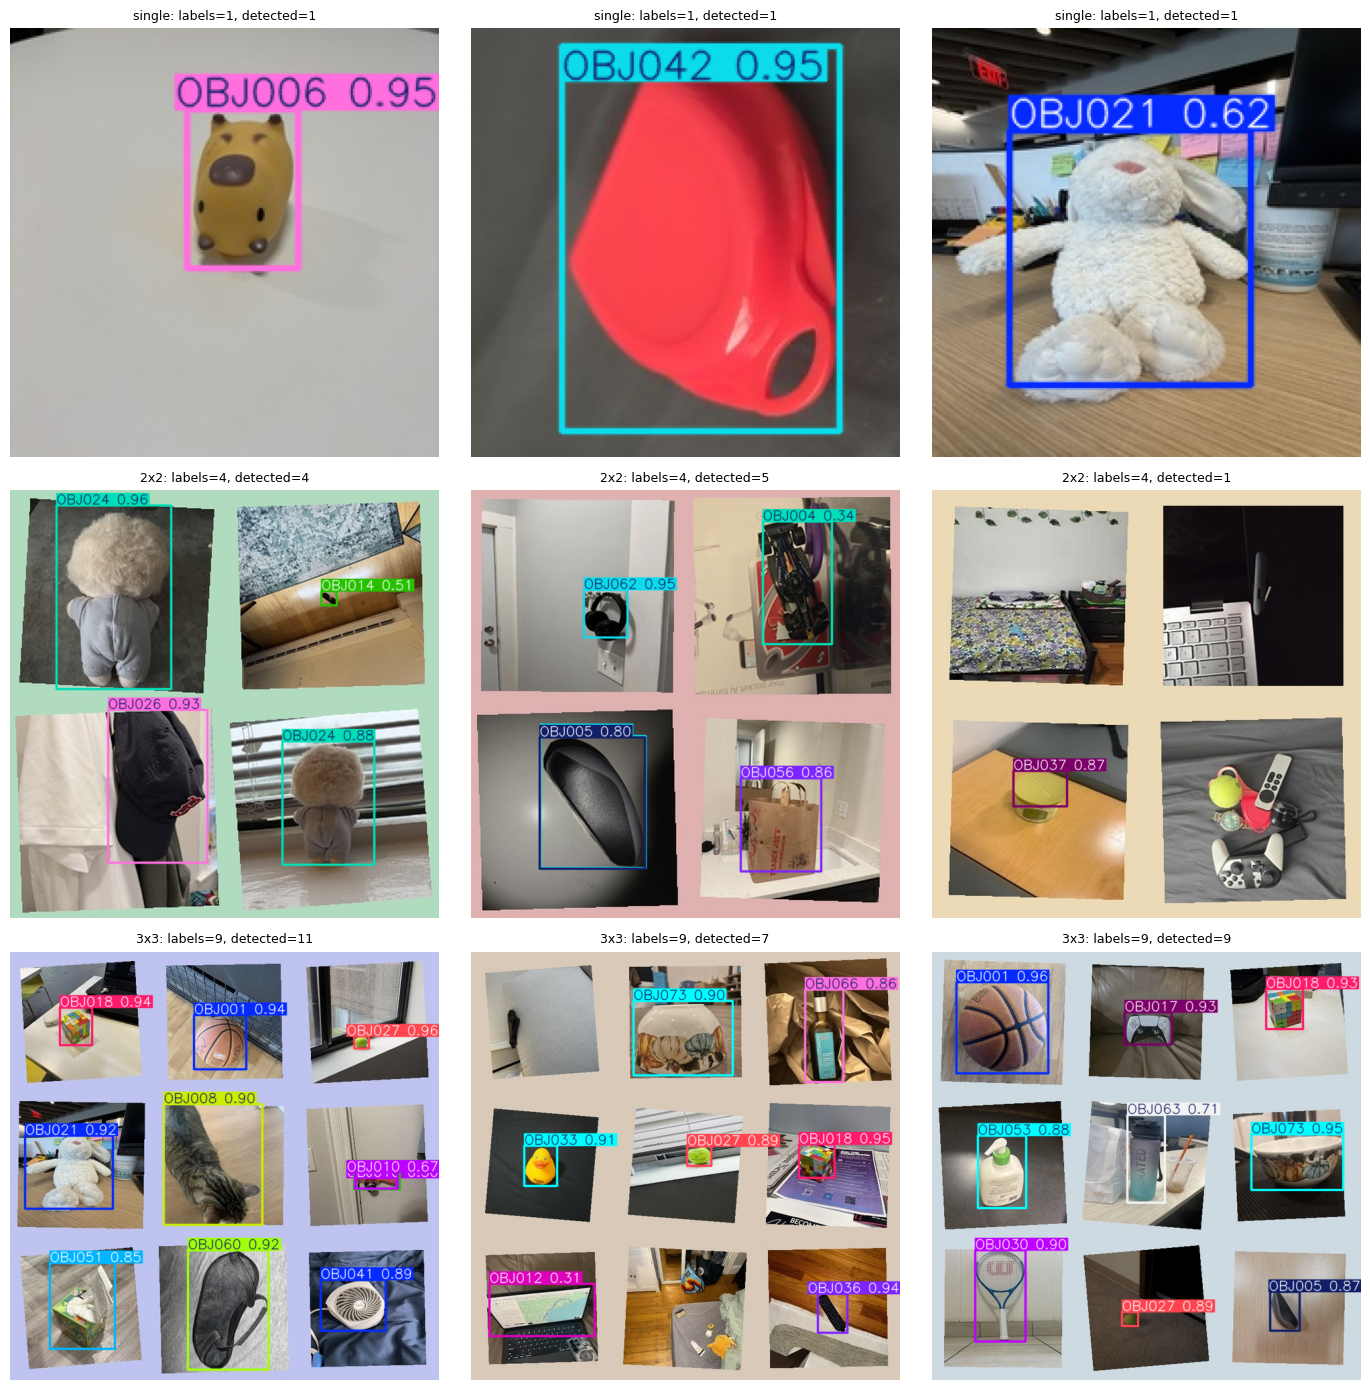

[02:59:51] Run complete.
Results: /content/drive/MyDrive/IE7615_outputs_milestone2_v5/run_20261019_020402_UTC_8158f013
Inference model: /content/drive/MyDrive/IE7615_outputs_milestone2_v5/run_20261019_020402_UTC_8158f013/models/v5_best.pt
Second model backup: /content/drive/MyDrive/IE7615_models/v5/run_20261019_020402_UTC_8158f013/v5_best.pt


In [21]:
fig, axes = plt.subplots(3,3,figsize=(14,14))
demo_rows = []
DEMO_DIR = LOCAL/'demo'
DEMO_DIR.mkdir(exist_ok=True)
for row, layout in enumerate(('single','2x2','3x3')):
    examples = [r for r in dataset_manifest if r['split']=='test' and r['layout']==layout]
    chosen = random.Random(SEED+1).sample(examples,3)
    for ax, record in zip(axes[row],chosen):
        path = DATASET/'images/test'/record['image']
        result = best.predict(str(path),imgsz=CANVAS,conf=0.25,iou=0.7,device=0,verbose=False)[0]
        plotted = result.plot()[...,::-1]
        ax.imshow(plotted)
        ax.set_title(f'{layout}: labels={len(record["objects"])}, detected={len(result.boxes)}',fontsize=9)
        ax.axis('off')
        output = DEMO_DIR/record['image']
        Image.fromarray(plotted).save(output,quality=95)
        copy_verified(output,OUT_DIR/'demo'/output.name)
        predictions = [{'id':result.names[int(b.cls.item())], 'bbox':[float(x) for x in b.xyxy[0].tolist()],
                        'confidence':float(b.conf.item())} for b in result.boxes]
        demo_rows.append({'image':record['image'],'layout':layout,'labels':record['objects'],'predictions':predictions})
plt.tight_layout()
plt.savefig(OUT_DIR/'detection_demo.png',dpi=130)
plt.show()
write_json(OUT_DIR/'demo/predictions.json',demo_rows)
say('Run complete.')
print('Results:',OUT_DIR)
print('Inference model:',MODEL_EXPORT)
print('Second model backup:',SECOND_EXPORT)
